# Example walkthrough (standalone, synthetic data)

This notebook is **fully standalone** -- it does not import anything from this repository's
`src/` folder, and it does not require the real (IRB-restricted) participant data. Every
number and figure below is generated from a small **synthetic** dataset created in this
notebook, purely to demonstrate that the pipeline's mechanics (preprocessing, resampling,
fitting, thresholding, SHAP, permutation importance) run end-to-end and are reproducible.

**None of the numbers in this notebook are the real study's results.** For the real study's
locked-in recipe and reported performance, see the [README](../README.md#methodology) and
the (forthcoming) paper. To reproduce the real results yourself, obtain data access per
[`data/README.md`](../data/README.md) and run `src/run_pipeline.py` against it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance

RNG = np.random.default_rng(42)
pd.set_option("display.max_colwidth", 60)

## Figure style (inlined from `src/utils/figure_style.py`)

Copied here, not imported, so this notebook has zero dependency on the rest of the repo.

In [2]:
import matplotlib
from matplotlib import font_manager

def use_times_style() -> None:
    """Inlined from src/utils/figure_style.py -- sets a Times-like typeface when available,
    falls back to matplotlib's default serif otherwise (so this still runs on any machine)."""
    try:
        matplotlib.rcParams["font.family"] = "STIXGeneral"
        matplotlib.rcParams["mathtext.fontset"] = "stix"
    except Exception:
        matplotlib.rcParams["font.family"] = "serif"
    matplotlib.rcParams["axes.unicode_minus"] = False

use_times_style()

## 1. Final locked-in recipe per target (for reference)

Each target (ODD, DICCD) was searched **independently** through a 4-stage nested-CV
comparison (Model -> Sampler -> Loss -> Hyperparameter) in the real study. The two targets
converged on genuinely different final recipes -- this table is reproduced from
`configs/recipes.yaml` (a config file, not a result) purely so the synthetic demo below can
use the same settings.

In [3]:
recipe = pd.DataFrame([
    {"item": "Sampler (train-only)", "ODD": "ADASYN (1:1)", "DICCD": "None (no resampling)"},
    {"item": "Loss", "ODD": "Focal (gamma=2.0)", "DICCD": "BCE (unweighted)"},
    {"item": "Split criterion", "ODD": "gini", "DICCD": "entropy"},
    {"item": "Max depth", "ODD": "None (unrestricted)", "DICCD": "12"},
    {"item": "Min samples per leaf", "ODD": "1", "DICCD": "1"},
    {"item": "Features per split", "ODD": "sqrt", "DICCD": "sqrt"},
])
recipe

,item,ODD,DICCD
0,Sampler (train-only),ADASYN (1:1),None (no resampling)
1,Loss,Focal (gamma=2.0),BCE (unweighted)
2,Split criterion,gini,entropy
3,Max depth,None (unrestricted),12
4,Min samples per leaf,1,1
5,Features per split,sqrt,sqrt


## 2. Synthetic dataset

A small synthetic cohort, shaped like the real schema described in
[`data/README.md`](../data/README.md): `other_features` / `adolescent_features` /
`adult_features` groups, a binary target with realistic class imbalance (~7% positive, close
to the real cohort's prevalence), and a mix of binary / continuous columns. **Fabricated
with `numpy`'s random generator -- not real participants, not the real effect sizes.**

In [4]:
N = 400
adolescent_cols = ["cyberbullying_victim", "cyberbullying_perp", "smartphone_addiction_z",
                    "academic_decline", "educational_screentime"]
adult_cols = ["parental_anxiety_high", "parental_depression_high", "maternal_education_college"]

X = pd.DataFrame({
    "cyberbullying_victim": RNG.binomial(1, 0.25, N),
    "cyberbullying_perp": RNG.binomial(1, 0.20, N),
    "smartphone_addiction_z": RNG.normal(0, 1, N),
    "academic_decline": RNG.binomial(1, 0.18, N),
    "educational_screentime": RNG.integers(1, 6, N),
    "parental_anxiety_high": RNG.binomial(1, 0.15, N),
    "parental_depression_high": RNG.binomial(1, 0.10, N),
    "maternal_education_college": RNG.binomial(1, 0.55, N),
})

# synthetic outcome: a weighted combination + noise, thresholded to ~7% positive
logit = (
    1.1 * X["cyberbullying_victim"] + 0.9 * X["smartphone_addiction_z"]
    + 0.6 * X["parental_anxiety_high"] + 0.4 * X["academic_decline"]
    + RNG.normal(0, 1.0, N) - 3.1
)
y = (logit > np.quantile(logit, 0.93)).astype(int)
print(f"N={N}, positive rate={y.mean():.3f}")
X.head()

N=400, positive rate=0.070


,cyberbullying_victim,cyberbullying_perp,smartphone_addiction_z,academic_decline,educational_screentime,parental_anxiety_high,parental_depression_high,maternal_education_college
0,1,0,1.728995,0,2,0,0,0
1,0,1,1.359221,0,5,0,0,1
2,1,0,0.255213,0,3,0,0,0
3,0,0,1.350625,0,2,0,0,1
4,0,1,0.012053,0,1,0,1,0


## 3. Fit the ODD recipe (ADASYN + Focal) on the synthetic split, score on held-out test

This mirrors the real pipeline's leakage-safety pattern: the imputer/scaler is fit on the
train split only, ADASYN resampling only ever touches the train split, and the test split is
scored exactly once. Focal-loss reweighting is implemented the same way as
`src/stage3_loss_comparison.py`: an unweighted warm-start fit, then a `sample_weight`-reweighted
refit on the same (resampled) train data.

In [5]:
from imblearn.over_sampling import ADASYN

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler().fit(X_tr)
X_tr_s = pd.DataFrame(scaler.transform(X_tr), columns=X.columns, index=X_tr.index)
X_te_s = pd.DataFrame(scaler.transform(X_te), columns=X.columns, index=X_te.index)

n_pos, n_neg = int((y_tr == 1).sum()), int((y_tr == 0).sum())
k = max(1, min(5, n_pos - 1))
X_res, y_res = ADASYN(sampling_strategy={1: n_neg}, random_state=42, n_neighbors=k).fit_resample(X_tr_s, y_tr)

def focal_sample_weight(y, p_pos, gamma=2.0):
    y = np.asarray(y); n = len(y)
    n_pos_, n_neg_ = max(int((y == 1).sum()), 1), max(int((y == 0).sum()), 1)
    alpha_pos, alpha_neg = n_neg_ / n, n_pos_ / n
    p = np.clip(p_pos, 1e-6, 1 - 1e-6)
    p_t = np.where(y == 1, p, 1 - p)
    alpha_t = np.where(y == 1, alpha_pos, alpha_neg)
    sw = alpha_t * (1 - p_t) ** gamma
    return np.clip(sw, 1e-3, None) * (n / np.clip(sw, 1e-3, None).sum())

warm = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(X_res, y_res)
p_warm = warm.predict_proba(X_res)[:, 1]
sw = focal_sample_weight(y_res.to_numpy(), p_warm)
clf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
clf.fit(X_res, y_res, sample_weight=sw)

scores_te = clf.predict_proba(X_te_s)[:, 1]
auc = roc_auc_score(y_te, scores_te)
print(f"Synthetic-data held-out AUC: {auc:.3f}  (illustrative only -- not a real result)")

Synthetic-data held-out AUC: 0.763  (illustrative only -- not a real result)


## 4. Youden threshold, confusion matrix (on the synthetic held-out split)

In [6]:
def youden_threshold(y_true, y_score):
    """Inlined from src/utils/models.py -- threshold maximizing TPR - FPR."""
    fpr, tpr, thresholds = roc_curve(y_true, y_score)
    j = tpr - fpr
    return float(thresholds[np.argmax(j)])

# threshold chosen from the (resampled) train-side scores only, never from the test fold
th = youden_threshold(y_res, clf.predict_proba(X_res)[:, 1])
pred_te = (scores_te >= th).astype(int)
tn, fp, fn, tp = confusion_matrix(y_te, pred_te).ravel()
print(f"threshold={th:.3f}")
pd.DataFrame([[tn, fp], [fn, tp]], index=["true 0", "true 1"], columns=["pred 0", "pred 1"])

threshold=0.673


,pred 0,pred 1
true 0,93,0
true 1,6,1


## 5. Permutation importance (held-out test fold only, synthetic data)

Same method as `src/permutation_importance.py`: `n_repeats=8`, `scoring="roc_auc"`, computed
on the held-out split only -- never on train (see the README's
[Methodology](../README.md#methodology) section for why).

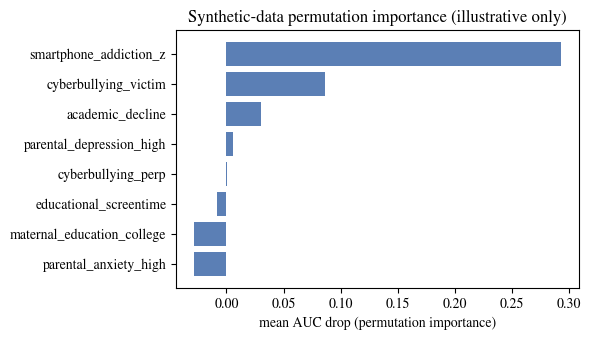

In [7]:
perm = permutation_importance(clf, X_te_s, y_te, scoring="roc_auc", n_repeats=8, random_state=42, n_jobs=-1)
perm_df = pd.DataFrame({"feature": X.columns, "delta_auc": perm.importances_mean}).sort_values("delta_auc", ascending=False)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(perm_df["feature"][::-1], perm_df["delta_auc"][::-1], color="#5b7fb5")
ax.set_xlabel("mean AUC drop (permutation importance)")
ax.set_title("Synthetic-data permutation importance (illustrative only)")
fig.tight_layout()
plt.show()

## Next steps

To see the **real** study's locked-in recipe and reported performance, read the
[README](../README.md#methodology). To reproduce the real results yourself: obtain data
access per [`data/README.md`](../data/README.md), place the files as documented, then run

```bash
python src/run_pipeline.py --target ODD --data-dir data --output-dir results/odd_nested
python src/run_pipeline.py --target DICCD --data-dir data --output-dir results/diccd_nested
```
